# Inpatient Claims — Exploratory Data Analysis

Standalone EDA on `data/raw/inpatient_raw.csv`, run **before** any cleaning or joining (see `01_data_loading_joining.ipynb` / `02_cleaning.ipynb`). Goal: understand this table's structure, quality, and key features on its own terms — missingness, reimbursement, claim duration, length of hospital stay, diagnosis/procedure codes — so decisions made in the cleaning and feature engineering steps are grounded in what the raw inpatient data actually looks like.

In [1]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)
sns.set_style('whitegrid')

from src.data_loader import RAW_DATA_DIR

inpatient = pd.read_csv(RAW_DATA_DIR / 'inpatient_raw.csv')

date_cols = ['ClaimStartDt', 'ClaimEndDt', 'AdmissionDt', 'DischargeDt']
for col in date_cols:
    inpatient[col] = pd.to_datetime(inpatient[col], errors='coerce')

inpatient.shape

(40474, 30)

## Shape & Columns

In [2]:
inpatient.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40474 entries, 0 to 40473
Data columns (total 30 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   BeneID                  40474 non-null  object        
 1   ClaimID                 40474 non-null  object        
 2   ClaimStartDt            40474 non-null  datetime64[ns]
 3   ClaimEndDt              40474 non-null  datetime64[ns]
 4   Provider                40474 non-null  object        
 5   InscClaimAmtReimbursed  40474 non-null  int64         
 6   AttendingPhysician      40362 non-null  object        
 7   OperatingPhysician      23830 non-null  object        
 8   OtherPhysician          4690 non-null   object        
 9   AdmissionDt             40474 non-null  datetime64[ns]
 10  ClmAdmitDiagnosisCode   40474 non-null  object        
 11  DeductibleAmtPaid       39575 non-null  float64       
 12  DischargeDt             40474 non-null  dateti

In [3]:
inpatient.head()

,BeneID,ClaimID,ClaimStartDt,ClaimEndDt,Provider,InscClaimAmtReimbursed,AttendingPhysician,OperatingPhysician,OtherPhysician,AdmissionDt,ClmAdmitDiagnosisCode,DeductibleAmtPaid,DischargeDt,DiagnosisGroupCode,ClmDiagnosisCode_1,ClmDiagnosisCode_2,ClmDiagnosisCode_3,ClmDiagnosisCode_4,ClmDiagnosisCode_5,ClmDiagnosisCode_6,ClmDiagnosisCode_7,ClmDiagnosisCode_8,ClmDiagnosisCode_9,ClmDiagnosisCode_10,ClmProcedureCode_1,ClmProcedureCode_2,ClmProcedureCode_3,ClmProcedureCode_4,ClmProcedureCode_5,ClmProcedureCode_6
0,BENE11001,CLM46614,2009-04-12,2009-04-18,PRV55912,26000,PHY390922,NaN,NaN,2009-04-12,7866,1068.0,2009-04-18,201,1970,4019,5853,7843,2768,71590,2724,19889,5849,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,BENE11001,CLM66048,2009-08-31,2009-09-02,PRV55907,5000,PHY318495,PHY318495,NaN,2009-08-31,6186,1068.0,2009-09-02,750,6186,2948,56400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7092.0,NaN,NaN,NaN,NaN,NaN
2,BENE11001,CLM68358,2009-09-17,2009-09-20,PRV56046,5000,PHY372395,NaN,PHY324689,2009-09-17,29590,1068.0,2009-09-20,883,29623,30390,71690,34590,V1581,32723,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,BENE11011,CLM38412,2009-02-14,2009-02-22,PRV52405,5000,PHY369659,PHY392961,PHY349768,2009-02-14,431,1068.0,2009-02-22,067,43491,2762,7843,32723,V1041,4254,25062,40390,4019,NaN,331.0,NaN,NaN,NaN,NaN,NaN
4,BENE11014,CLM63689,2009-08-13,2009-08-30,PRV56614,10000,PHY379376,PHY398258,NaN,2009-08-13,78321,1068.0,2009-08-30,975,042,3051,34400,5856,42732,486,5119,29620,20300,NaN,3893.0,NaN,NaN,NaN,NaN,NaN


## Missing Values

Per `data/raw/raw_data.md`, several columns are *structurally* sparse rather than data-quality problems: `OperatingPhysician`/`OtherPhysician` (missing = no operation / no additional physician), and `ClmDiagnosisCode_5..10` / `ClmProcedureCode_3..6` (most claims only use a handful of slots).

In [4]:
missing = pd.DataFrame({
    'n_missing': inpatient.isna().sum(),
    'pct_missing': (inpatient.isna().mean() * 100).round(2),
    'dtype': inpatient.dtypes,
})
missing.sort_values('pct_missing', ascending=False)

,n_missing,pct_missing,dtype
ClmProcedureCode_6,40474,100.00,float64
ClmProcedureCode_5,40465,99.98,float64
ClmProcedureCode_4,40358,99.71,float64
ClmProcedureCode_3,39509,97.62,float64
ClmDiagnosisCode_10,36547,90.30,object
OtherPhysician,35784,88.41,object
ClmProcedureCode_2,35020,86.52,float64
ClmProcedureCode_1,17326,42.81,float64
OperatingPhysician,16644,41.12,object
ClmDiagnosisCode_9,13497,33.35,object


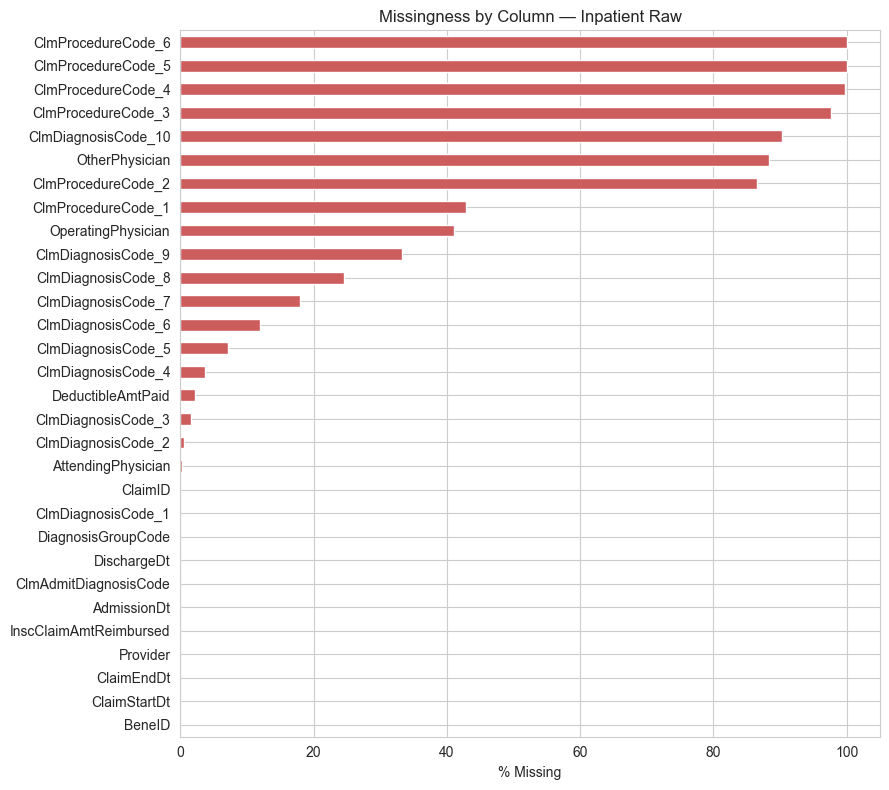

In [5]:
missing_pct = missing['pct_missing'].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 8))
missing_pct.plot(kind='barh', ax=ax, color='indianred')
ax.invert_yaxis()
ax.set_xlabel('% Missing')
ax.set_title('Missingness by Column — Inpatient Raw')
plt.tight_layout()
plt.show()

## Row-Level Integrity Checks

In [6]:
print('Total rows:', len(inpatient))
print('Unique ClaimID:', inpatient['ClaimID'].nunique())
print('Duplicate ClaimID rows:', inpatient['ClaimID'].duplicated().sum())
print('Fully duplicated rows:', inpatient.duplicated().sum())
print('Unique BeneID (patients):', inpatient['BeneID'].nunique())
print('Unique Provider:', inpatient['Provider'].nunique())

Total rows: 40474
Unique ClaimID: 40474
Duplicate ClaimID rows: 0
Fully duplicated rows: 0
Unique BeneID (patients): 31289
Unique Provider: 2092


## Claim Duration & Length of Hospital Stay

In [7]:
print('ClaimStartDt range:', inpatient['ClaimStartDt'].min(), '->', inpatient['ClaimStartDt'].max())
print('AdmissionDt range:  ', inpatient['AdmissionDt'].min(), '->', inpatient['AdmissionDt'].max())

inpatient['ClaimDuration'] = (inpatient['ClaimEndDt'] - inpatient['ClaimStartDt']).dt.days
inpatient['LengthOfStay'] = (inpatient['DischargeDt'] - inpatient['AdmissionDt']).dt.days

inpatient[['ClaimDuration', 'LengthOfStay']].describe()

ClaimStartDt range: 2008-11-27 00:00:00 -> 2009-12-31 00:00:00
AdmissionDt range:   2008-11-27 00:00:00 -> 2009-12-31 00:00:00


,ClaimDuration,LengthOfStay
count,40474.000000,40474.000000
mean,5.660251,5.665168
std,5.628873,5.638538
min,0.000000,0.000000
25%,2.000000,2.000000
50%,4.000000,4.000000
75%,7.000000,7.000000
max,36.000000,35.000000


In [8]:
print('Negative ClaimDuration rows:', (inpatient['ClaimDuration'] < 0).sum())
print('Negative LengthOfStay rows:', (inpatient['LengthOfStay'] < 0).sum())
print('ClaimDuration == 0 rows (same-day claims):', (inpatient['ClaimDuration'] == 0).sum())

mismatch = (inpatient['ClaimStartDt'] != inpatient['AdmissionDt']).sum()
print(f'Rows where ClaimStartDt != AdmissionDt: {mismatch} ({mismatch / len(inpatient) * 100:.1f}%)')

Negative ClaimDuration rows: 0
Negative LengthOfStay rows: 0
ClaimDuration == 0 rows (same-day claims): 605
Rows where ClaimStartDt != AdmissionDt: 32 (0.1%)


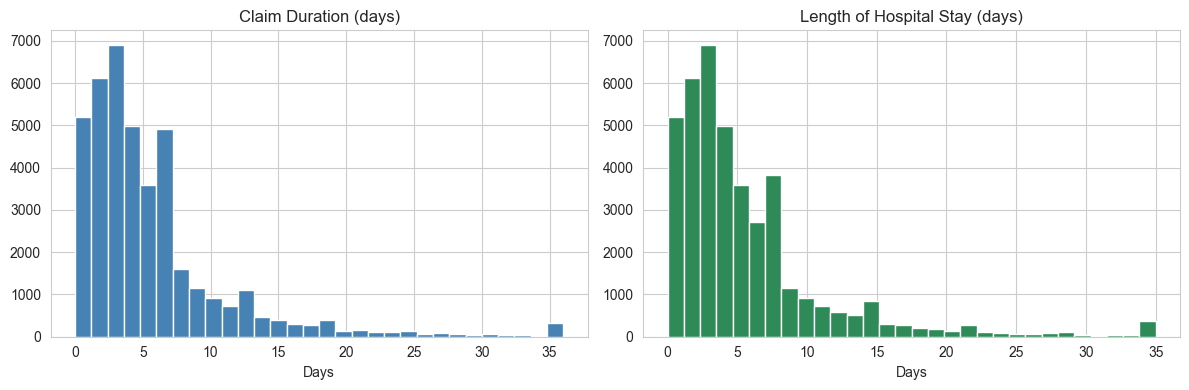

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(inpatient['ClaimDuration'].dropna(), bins=30, color='steelblue')
axes[0].set_title('Claim Duration (days)')
axes[0].set_xlabel('Days')

axes[1].hist(inpatient['LengthOfStay'].dropna(), bins=30, color='seagreen')
axes[1].set_title('Length of Hospital Stay (days)')
axes[1].set_xlabel('Days')
plt.tight_layout()
plt.show()

## Reimbursement & Deductible Amounts

In [10]:
inpatient[['InscClaimAmtReimbursed', 'DeductibleAmtPaid']].describe()

,InscClaimAmtReimbursed,DeductibleAmtPaid
count,40474.000000,39575.0
mean,10087.884074,1068.0
std,10303.099402,0.0
min,0.000000,1068.0
25%,4000.000000,1068.0
50%,7000.000000,1068.0
75%,12000.000000,1068.0
max,125000.000000,1068.0


Zero-reimbursement claims: 1085
Zero-deductible claims:     0


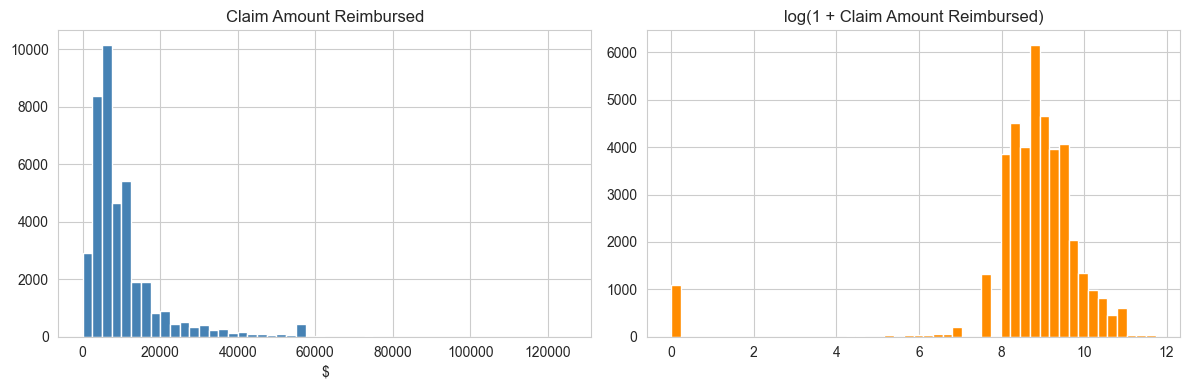

In [11]:
print('Zero-reimbursement claims:', (inpatient['InscClaimAmtReimbursed'] == 0).sum())
print('Zero-deductible claims:    ', (inpatient['DeductibleAmtPaid'] == 0).sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(inpatient['InscClaimAmtReimbursed'], bins=50, color='steelblue')
axes[0].set_title('Claim Amount Reimbursed')
axes[0].set_xlabel('$')

axes[1].hist(np.log1p(inpatient['InscClaimAmtReimbursed']), bins=50, color='darkorange')
axes[1].set_title('log(1 + Claim Amount Reimbursed)')
plt.tight_layout()
plt.show()

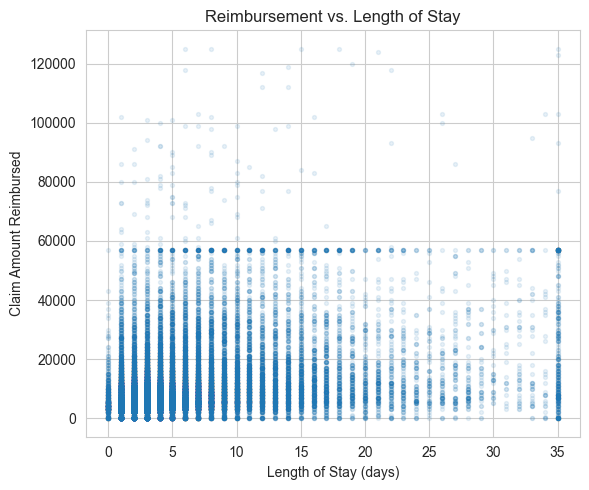

Correlation (LengthOfStay, InscClaimAmtReimbursed): 0.322


In [12]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(inpatient['LengthOfStay'], inpatient['InscClaimAmtReimbursed'], alpha=0.1, s=8)
ax.set_xlabel('Length of Stay (days)')
ax.set_ylabel('Claim Amount Reimbursed')
ax.set_title('Reimbursement vs. Length of Stay')
plt.tight_layout()
plt.show()

print('Correlation (LengthOfStay, InscClaimAmtReimbursed):',
      inpatient[['LengthOfStay', 'InscClaimAmtReimbursed']].corr().iloc[0, 1].round(3))

## Diagnosis Codes

In [13]:
print('Top 10 admission diagnosis codes (ClmAdmitDiagnosisCode):')
inpatient['ClmAdmitDiagnosisCode'].value_counts().head(10)

Top 10 admission diagnosis codes (ClmAdmitDiagnosisCode):


ClmAdmitDiagnosisCode
78650    1731
78605    1669
486      1438
4280     1106
7802     1018
V5789     960
78097     859
78900     786
78079     781
49121     651
Name: count, dtype: int64

In [14]:
print('Top 10 primary diagnosis codes (ClmDiagnosisCode_1):')
inpatient['ClmDiagnosisCode_1'].value_counts().head(10)

Top 10 primary diagnosis codes (ClmDiagnosisCode_1):


ClmDiagnosisCode_1
486      1499
V5789    1158
41401    1088
49121     974
0389      945
5990      844
4280      825
42731     760
41071     718
71536     713
Name: count, dtype: int64

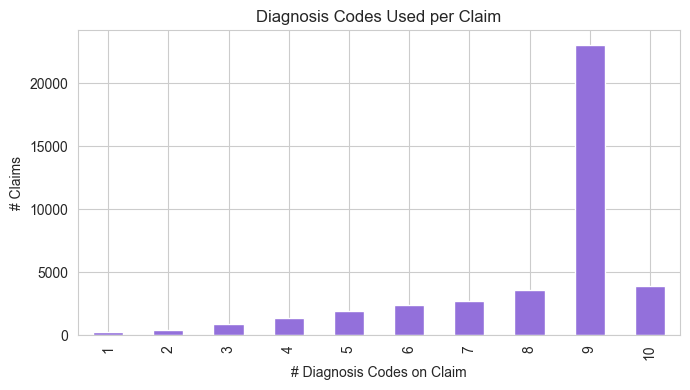

In [15]:
diag_cols = [f'ClmDiagnosisCode_{i}' for i in range(1, 11)]
inpatient['NumDiagnosisCodes'] = inpatient[diag_cols].notna().sum(axis=1)

fig, ax = plt.subplots(figsize=(7, 4))
inpatient['NumDiagnosisCodes'].value_counts().sort_index().plot(kind='bar', ax=ax, color='mediumpurple')
ax.set_xlabel('# Diagnosis Codes on Claim')
ax.set_ylabel('# Claims')
ax.set_title('Diagnosis Codes Used per Claim')
plt.tight_layout()
plt.show()

## Procedure Codes

In [16]:
print('Top 10 primary procedure codes (ClmProcedureCode_1):')
print(inpatient['ClmProcedureCode_1'].value_counts().head(10))

proc_cols = [f'ClmProcedureCode_{i}' for i in range(1, 7)]
inpatient['NumProcedureCodes'] = inpatient[proc_cols].notna().sum(axis=1)
inpatient['NumProcedureCodes'].value_counts().sort_index()

Top 10 primary procedure codes (ClmProcedureCode_1):
ClmProcedureCode_1
9904.0    1137
8154.0    1021
66.0       893
3893.0     849
3995.0     805
4516.0     643
3722.0     581
8151.0     462
8872.0     409
9671.0     401
Name: count, dtype: int64


NumProcedureCodes
0    17326
1    17694
2     4489
3      849
4      107
5        9
Name: count, dtype: int64

## Diagnosis-Related Group (DRG) Codes

In [17]:
print('Top 10 DiagnosisGroupCode (DRG):')
inpatient['DiagnosisGroupCode'].value_counts().head(10)

Top 10 DiagnosisGroupCode (DRG):


DiagnosisGroupCode
882    179
884    174
166    168
183    165
939    163
168    160
883    160
887    159
204    158
945    156
Name: count, dtype: int64

## Physician Involvement

In [18]:
for col in ['AttendingPhysician', 'OperatingPhysician', 'OtherPhysician']:
    print(f"{col}: {inpatient[col].notna().mean() * 100:.1f}% present, {inpatient[col].nunique()} unique")

phys_cols = ['AttendingPhysician', 'OperatingPhysician', 'OtherPhysician']
inpatient['NumPhysiciansInvolved'] = inpatient[phys_cols].notna().sum(axis=1)
inpatient['NumPhysiciansInvolved'].value_counts().sort_index()

AttendingPhysician: 99.7% present, 11604 unique
OperatingPhysician: 58.9% present, 8287 unique
OtherPhysician: 11.6% present, 2877 unique


NumPhysiciansInvolved
0      106
1    15265
2    21692
3     3411
Name: count, dtype: int64

## Claim Volume per Provider & Beneficiary

Providers with >=1 inpatient claim: 2092 | median claims/provider: 8.0
Beneficiaries with >=1 inpatient claim: 31289 | median claims/beneficiary: 1.0


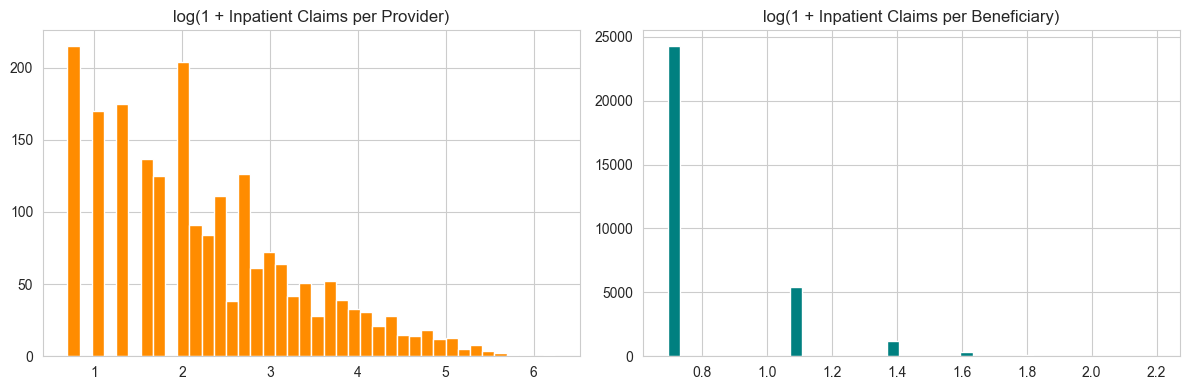

In [19]:
claims_per_provider = inpatient.groupby('Provider')['ClaimID'].count().sort_values(ascending=False)
claims_per_bene = inpatient.groupby('BeneID')['ClaimID'].count().sort_values(ascending=False)

print('Providers with >=1 inpatient claim:', inpatient['Provider'].nunique(),
      '| median claims/provider:', claims_per_provider.median())
print('Beneficiaries with >=1 inpatient claim:', inpatient['BeneID'].nunique(),
      '| median claims/beneficiary:', claims_per_bene.median())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(np.log1p(claims_per_provider), bins=40, color='darkorange')
axes[0].set_title('log(1 + Inpatient Claims per Provider)')
axes[1].hist(np.log1p(claims_per_bene), bins=40, color='teal')
axes[1].set_title('log(1 + Inpatient Claims per Beneficiary)')
plt.tight_layout()
plt.show()

In [20]:
print('Top 10 beneficiaries by inpatient claim count (repeat-patient signal):')
claims_per_bene.head(10)

Top 10 beneficiaries by inpatient claim count (repeat-patient signal):


BeneID
BENE134170    8
BENE64791     7
BENE119457    7
BENE121796    7
BENE62091     7
BENE117116    7
BENE31905     6
BENE13119     6
BENE78733     6
BENE55873     6
Name: ClaimID, dtype: int64

## Fraud Label Context

The target label lives at the provider level (`provider_labels.csv`), not on the claims table itself. Joining it in here — purely for EDA, not as part of the cleaning pipeline — shows whether inpatient-claim-level features already separate fraud groups before any feature engineering.

In [21]:
labels = pd.read_csv(RAW_DATA_DIR / 'provider_labels.csv')
inpatient_labeled = inpatient.merge(labels, on='Provider', how='left')
inpatient_labeled['PotentialFraud'] = inpatient_labeled['PotentialFraud'].map({'Yes': 1, 'No': 0})

inpatient_labeled.groupby('PotentialFraud')[
    ['InscClaimAmtReimbursed', 'DeductibleAmtPaid', 'ClaimDuration', 'LengthOfStay', 'NumPhysiciansInvolved']
].mean().round(2)

,InscClaimAmtReimbursed,DeductibleAmtPaid,ClaimDuration,LengthOfStay,NumPhysiciansInvolved
PotentialFraud,,,,,
0,9782.60,1068.0,5.55,5.56,1.72
1,10310.59,1068.0,5.74,5.74,1.69


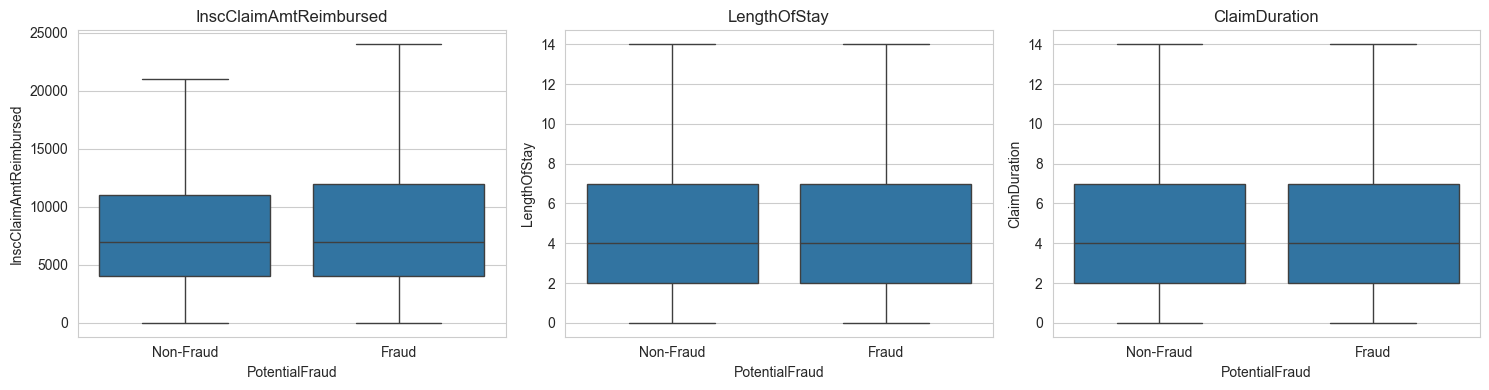

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['InscClaimAmtReimbursed', 'LengthOfStay', 'ClaimDuration']):
    sns.boxplot(data=inpatient_labeled, x='PotentialFraud', y=col, ax=ax, showfliers=False)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Non-Fraud', 'Fraud'])
    ax.set_title(col)
plt.tight_layout()
plt.show()

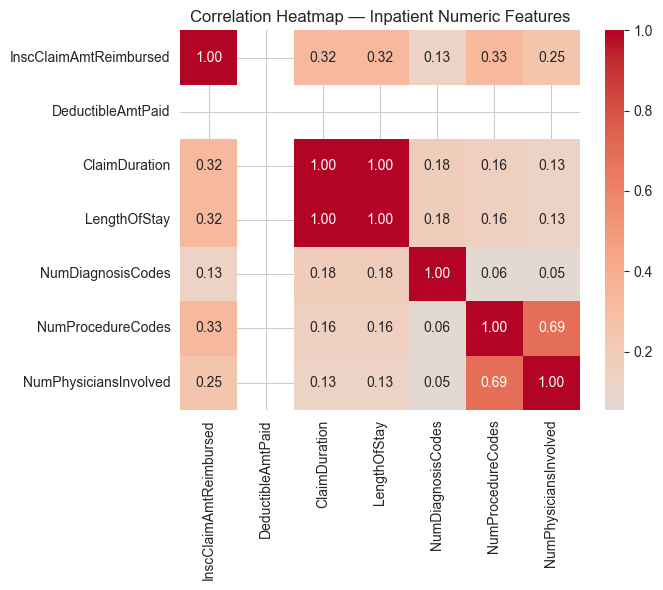

In [23]:
numeric_cols = ['InscClaimAmtReimbursed', 'DeductibleAmtPaid', 'ClaimDuration', 'LengthOfStay',
                'NumDiagnosisCodes', 'NumProcedureCodes', 'NumPhysiciansInvolved']
corr = inpatient_labeled[numeric_cols].corr()
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation Heatmap — Inpatient Numeric Features')
plt.tight_layout()
plt.show()

## Summary of Findings

**Shape & integrity**
- 40,474 inpatient claims, 30 raw columns. `ClaimID` is unique (no duplicate claims), and there are no fully duplicated rows — the table is clean at the row level.
- 31,289 unique beneficiaries but only 2,092 unique providers. Median is **1 inpatient claim per beneficiary** vs. **8 inpatient claims per provider** — provider is the far more repeated key, which is consistent with the fraud label living at the provider grain.

**Missingness — mostly structural, not data-quality issues**
- `ClmProcedureCode_3..6` and `ClmDiagnosisCode_10` are 90-100% empty — most claims simply don't use that many code slots.
- `OtherPhysician` (88% missing) and `OperatingPhysician` (41% missing) reflect that most claims don't involve an additional physician or a procedure — not missing data.
- `AttendingPhysician` is missing on only 0.3% of claims.
- **`DeductibleAmtPaid` is the one to watch**: only 2.2% missing, but every non-missing value is exactly **$1,068** (std = 0). As a raw numeric feature it carries zero variance/information for this data — if it's used downstream, only its *missingness flag* (899 rows) could plausibly carry signal, not the value itself.

**Claim duration & length of stay**
- `ClaimDuration` (`ClaimEndDt - ClaimStartDt`) and `LengthOfStay` (`DischargeDt - AdmissionDt`) have nearly identical distributions (mean ≈5.66 days, median 4, max 36/35 days), because `ClaimStartDt` matches `AdmissionDt` in 99.9% of rows. **These two derived features are redundant** — one can likely be dropped, or kept as a consistency check.
- No negative durations anywhere (internally consistent dates). 605 claims (1.5%) are same-day (duration = 0).

**Reimbursement**
- `InscClaimAmtReimbursed`: mean $10,088, median $7,000, right-skewed, max $125,000.
- 1,085 claims (2.7%) have **$0 reimbursed** — worth checking downstream whether these are denied claims or fully covered by the deductible, since they behave differently from the bulk of the distribution.
- Correlation between `LengthOfStay` and reimbursement is only **0.32** — a longer stay only weakly predicts a higher bill on its own; diagnosis/procedure complexity likely matters more.

**Diagnosis & procedure codes**
- Top admission diagnosis is `78650` (n=1,731); top primary diagnosis (`ClmDiagnosisCode_1`) is `486` (pneumonia, n=1,499), followed by `V5789` (n=1,158).
- 42.8% of claims (17,326) have **zero procedure codes** at all — inpatient stays without a recorded procedure are the norm, not the exception, in this dataset.
- DRG (`DiagnosisGroupCode`) is fairly evenly spread — the most common code accounts for only 179/40,474 claims, so no single DRG dominates.
- All of `ClmDiagnosisCode_*`, `ClmProcedureCode_*`, and `DiagnosisGroupCode` are **high-cardinality categoricals** — plan for frequency/target encoding or ICD-9-chapter grouping rather than one-hot encoding downstream.

**Physician involvement**
- Most claims involve 1-2 physicians (15,265 with 1, 21,692 with 2, 3,411 with 3). 106 claims list **zero** physicians at all — a small edge case worth a sanity check before cleaning.

**Fraud label context (claim-level, provider label joined in for reference only)**
- At the raw claim level, Fraud vs. Non-Fraud group means look **nearly identical** — reimbursed $10,311 vs. $9,783, stay 5.74 vs. 5.56 days, physicians involved 1.69 vs. 1.72. Claim-level averages don't cleanly separate the classes.
- This matches the project's existing convention (see `03_eda_stats.ipynb`): claims from the same provider aren't independent, and the fraud label is provider-level, so **statistical comparisons and modeling features should be built on provider-level aggregates** (e.g. `NumClaims`, volume/rate-based features), not raw per-claim values.

**Implications for cleaning / feature engineering**
1. Keep one of `ClaimDuration` / `LengthOfStay` (they're redundant here); `LengthOfStay` is the more inpatient-specific name.
2. Treat `DeductibleAmtPaid` as near-constant — likely drop as a numeric feature, optionally keep `IsDeductibleMissing` as a flag.
3. Engineer `NumDiagnosisCodes`, `NumProcedureCodes`, `NumPhysiciansInvolved`, `HasOperation` (`OperatingPhysician` not null), and `IsZeroReimbursement` as claim-level features — all computed above.
4. Aggregate to provider level (claim counts, mean/sum reimbursement, mean stay length, procedure/diagnosis code diversity) before running fraud comparisons or feeding a model — raw claim-level values are too noisy/independent-violating on their own.
5. High-cardinality code columns need encoding strategy decided before feature engineering (frequency encoding or ICD-9 chapter grouping recommended over one-hot, given cardinality).